# Kick out limit with different masses


## Notes on Critical ξ vs. Redshift Bin

### Physical regimes

#### Low-mass regime (log₁₀(mₐ/eV) ≥ −30.7)

For log₁₀(mₐ/eV) = −31.0, −30.9, −30.8, −30.7, ξ_crit increases monotonically with z.
This is the expected behaviour: at higher redshift H(z) is larger, so a stronger kick ξ is required to overcome Hubble friction and push the field over the potential barrier.
The field is still "slow" relative to the oscillation timescale of the potential — the kick has to do more work against friction.

#### Transition regime (log₁₀(mₐ/eV) ≈ −30.6 / −30.5)

A local minimum appears around z ~ 25–35.
This is physically interesting: there exists an optimal redshift bin in which the field is particularly sensitive to the kick, meaning a very small ξ suffices to trigger kick-out.
This likely corresponds to the region where the axion mass becomes comparable to the Hubble rate at that bin, i.e. mₐ ~ H(z_bin) — the field is about to start oscillating and the near-resonant condition makes the kick maximally efficient.

#### High-mass regime (log₁₀(mₐ/eV) ≤ −30.4)

Kick-out becomes easier at high z (ξ_crit decreases with increasing z) and the minimum shifts progressively towards z ~ 60–80.
At log₁₀(mₐ/eV) = −30.0 the curve is nearly flat and very low (~0.004) for z > 40 — the field is already oscillating rapidly and almost any injection amplitude drives it over the barrier.

### The minimum as a proxy for the oscillation onset

The redshift of the minimum ξ_crit is a direct proxy for the moment when the axion starts oscillating, defined by the condition:

$$m_a \approx 3 H(z_{\rm osc})$$

As log₁₀(mₐ/eV) increases (heavier axion), z_osc shifts to higher redshift — which is exactly the systematic trend visible across the panel grid.

### Numerical robustness

A convergence test varying the regularisation parameter ε in the source term

$$S = \frac{Q \, \dot\phi}{\dot\phi^2 + \varepsilon^2}$$

over the range ε ∈ {10⁻⁶, 10⁻⁸, 10⁻¹⁰} yields an identical ξ_crit = 0.015869 for the test case (log₁₀(mₐ/eV) = −30.5, bin z = 40–30).
This confirms that |φ̇| ≫ ε along the trajectory and that the critical values reported are not numerical artefacts of the regularisation.

# Single mass case

In [1]:
import numpy as np
import local
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
import os

# Visual settings
%config InlineBackend.figure_format='retina'
%matplotlib inline

if '/Library/TeX/texbin/' not in os.environ["PATH"]:
    os.environ["PATH"] += os.pathsep + '/Library/TeX/texbin/'
    
# Latex font
plt.rc('font', **{'family': 'serif', 'serif': ['Computer Modern']})
plt.rc('text', usetex=True)


%matplotlib inline
%config InlineBackend.figure_format = 'retina'
from matplotlib import colors
#plt.rcParams['figure.figsize'] = [9,7]  # Adjust the size as needed for the plots
from mpl_toolkits.mplot3d import Axes3D



In [2]:
#Fixed parameters for the phi dynamics and injection

logm = -30.50
tf, n = 100, 1
theta_ini = 0.01

eps = 1e-8 
rtol, atol = 1e-5, 1e-7
bphi0_ini, bphi1_ini = theta_ini * tf, 0.



a = np.logspace(-6, 0, 2000)
a_ini = a[0]
z = 1./a - 1.

# Definition of the redsfhift bins
z_bins = [
    (20, 10),
    (30, 20),
    (40, 30),
    (50, 40),
    (60, 50),
    (70, 60),
    (80, 70),
    (90, 80),
    (100, 90),
    #(110, 100),
    #(120, 110),
    #(130, 120),
    #(140, 130),
    #(150, 140)
]

In [3]:
#Defining the functions to search xi_crit before the kick-out for a given z_bin

def is_stable(xi, z_start, z_end):
    """Check whether the axion field stays below the kick-out limit for a given (z_start, z_end) bin."""
    phi = solve_ivp(local.EoM_phi, [a[0], 1], [bphi0_ini, bphi1_ini],
                    t_eval=a, args=[logm, tf, n, xi, eps, z_start, z_end, bphi0_ini],
                    atol=atol, rtol=rtol, method="RK45", max_step=1e-4)

    if not phi.success:
        return False

    # Kick-out happens when the cosine potential peak is overtaken (+- pi * t_f)
    limit_kickout = np.pi * tf
    if np.any(phi.y[0] < -limit_kickout) or np.any(phi.y[0] > limit_kickout):
        return False

    return True


def find_critical_xi(z_start, z_end, xi_min=0.0, xi_max=10.0, tol=1e-5):
    """Binary search for the maximum xi before kick-out, for a given z_bin."""
    low = xi_min
    high = xi_max

    if is_stable(high, z_start, z_end):
        return high

    while (high - low) > tol:
        mid = (low + high) / 2.0
        if is_stable(mid, z_start, z_end):
            low = mid
        else:
            high = mid

    return low



In [4]:
# Loop over the different redshift bins

print(f"Starting search for log10(m_a/eV) = {logm}\n")
critical_values = {}


for z_start, z_end in z_bins:
    print(f"Analyzing bin Delta_z = {z_start} -> {z_end}...")
    
    
    xi_crit = find_critical_xi(z_start, z_end, xi_min=0.0, xi_max=10.0, tol=1e-6)
    
    critical_values[f"{z_start}-{z_end}"] = xi_crit
    print(f"--> Critical kick-out value: xi = {xi_crit:.5e}\n")

Starting search for log10(m_a/eV) = -30.5

Analyzing bin Delta_z = 20 -> 10...
--> Critical kick-out value: xi = 2.39474e-02

Analyzing bin Delta_z = 30 -> 20...
--> Critical kick-out value: xi = 1.71912e-02

Analyzing bin Delta_z = 40 -> 30...
--> Critical kick-out value: xi = 1.58685e-02

Analyzing bin Delta_z = 50 -> 40...
--> Critical kick-out value: xi = 1.57923e-02

Analyzing bin Delta_z = 60 -> 50...
--> Critical kick-out value: xi = 1.63025e-02

Analyzing bin Delta_z = 70 -> 60...
--> Critical kick-out value: xi = 1.70732e-02

Analyzing bin Delta_z = 80 -> 70...
--> Critical kick-out value: xi = 1.79917e-02

Analyzing bin Delta_z = 90 -> 80...
--> Critical kick-out value: xi = 1.90789e-02

Analyzing bin Delta_z = 100 -> 90...
--> Critical kick-out value: xi = 2.01774e-02



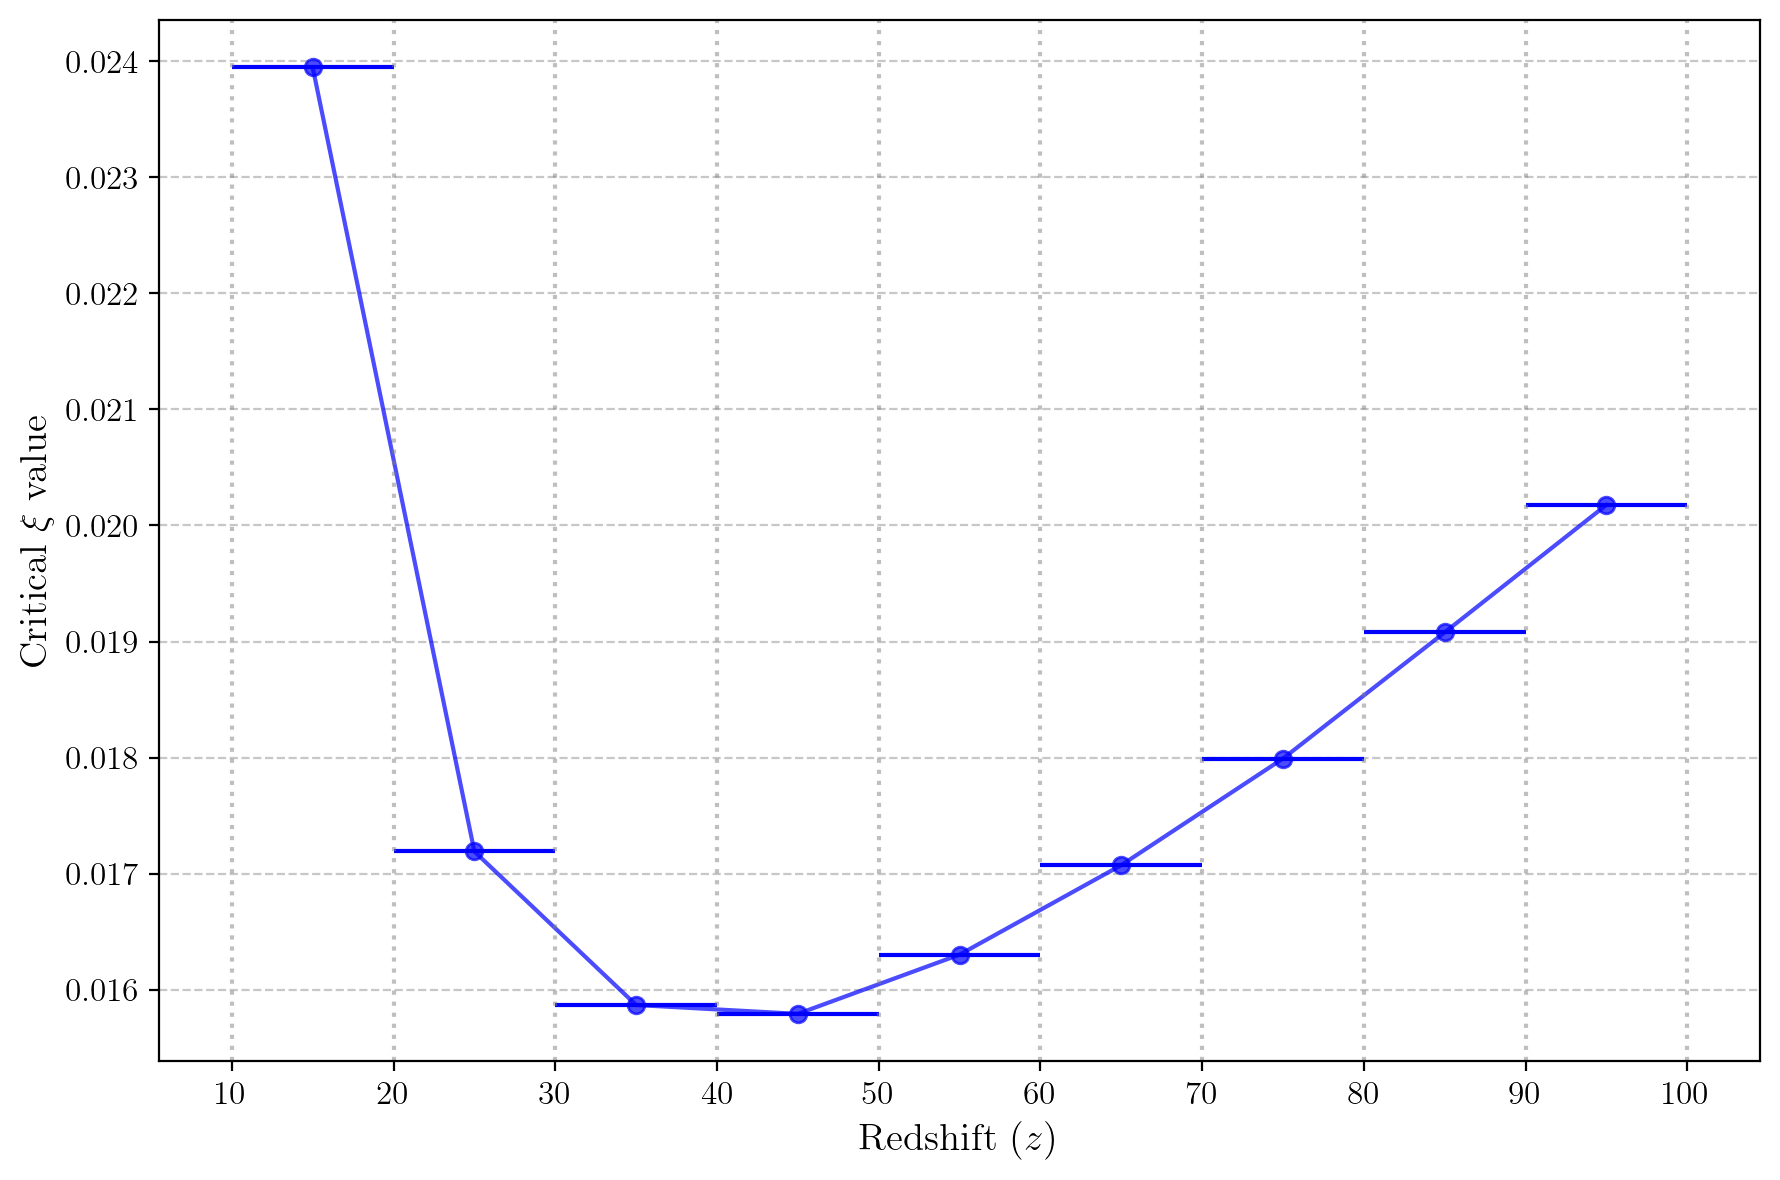

In [5]:
# xi_critical vs \Delta z


xi_values = list(critical_values.values())
z_centers = [(z_start + z_end) / 2.0 for z_start, z_end in z_bins]
z_edges = sorted(list(set([z for bin_tuple in z_bins for z in bin_tuple])))

#Plotting 

plt.figure(figsize=(9, 6))
plt.plot(z_centers, xi_values, marker='o', linestyle='-', color='b', markersize=6, linewidth=1.5, alpha=0.7)
for (z_start, z_end), xi in zip(z_bins, xi_values):
    z_min = min(z_start, z_end)
    z_max = max(z_start, z_end)
    plt.hlines(y=xi, xmin=z_min, xmax=z_max, color='b', linestyle='-', linewidth=1.5)
plt.xlabel('Redshift ($z$)', fontsize=14)
plt.ylabel(r'Critical $\xi$ value', fontsize=14)
plt.xticks(z_edges, fontsize=12)
plt.yticks(fontsize=12)
for edge in z_edges:
    plt.axvline(x=edge, color='gray', linestyle=':', alpha=0.5)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout() 

#plt.savefig("critical_xi_vs_redshift_combined.png", dpi=300)
plt.show()

## $\xi_{crit}$ for different masses

In [6]:
# 10 linearly spaced mass values from 10^-31.0 to 10^-30.0 eV

logm_values = np.linspace(-31.0, -30.0, 11)

In [7]:
# Redefine the searching function to explicitly accept current_logm. Here we use a faster version of the functions.


def is_stable(xi, z_start, z_end, current_logm):
    """
    Solves the system and checks for instability (kick-out).
    """
    phi = solve_ivp(local.EoM_phi, [a[0], 1], [bphi0_ini, bphi1_ini], 
                    t_eval=a, args=[current_logm, tf, n, xi, eps, z_start, z_end], 
                    atol=atol, rtol=rtol, method="RK45")
    
    if not phi.success:
        return False
    
    limit_kickout = np.pi * tf
    
    if phi.y[0][-1] < -limit_kickout or phi.y[0][-1] > limit_kickout: 
        return False
        
    return True

def find_critical_xi(z_start, z_end, current_logm, xi_min=1e-5, xi_max=1.0, tol=1e-6):
    """
    Performs a binary search to find the maximum value of xi before the kick-out.
    """
    low = xi_min
    high = xi_max
    
    if is_stable(high, z_start, z_end, current_logm):
        return high
        
    while (high - low) > tol:
        mid = (low + high) / 2.0
        
        if is_stable(mid, z_start, z_end, current_logm):
            low = mid
        else:
            high = mid
            
    return low

In [8]:
# Main computation loop
all_critical_values = {}

for current_logm in logm_values:
    print(f"Starting search for log10(m_a/eV) = {current_logm:.2f}")
    critical_values = {}
    
    for z_start, z_end in z_bins:
        # We can pass a higher xi_max if you expect values larger than 1.0 at lower masses
        xi_crit = find_critical_xi(z_start, z_end, current_logm, xi_min=0.0, xi_max=1.0, tol=1e-6)
        critical_values[f"{z_start}-{z_end}"] = xi_crit
        
    all_critical_values[current_logm] = critical_values
    print("--> Search completed for this mass.\n")


Starting search for log10(m_a/eV) = -31.00
--> Search completed for this mass.

Starting search for log10(m_a/eV) = -30.90
--> Search completed for this mass.

Starting search for log10(m_a/eV) = -30.80
--> Search completed for this mass.

Starting search for log10(m_a/eV) = -30.70
--> Search completed for this mass.

Starting search for log10(m_a/eV) = -30.60
--> Search completed for this mass.

Starting search for log10(m_a/eV) = -30.50
--> Search completed for this mass.

Starting search for log10(m_a/eV) = -30.40
--> Search completed for this mass.

Starting search for log10(m_a/eV) = -30.30
--> Search completed for this mass.

Starting search for log10(m_a/eV) = -30.20
--> Search completed for this mass.

Starting search for log10(m_a/eV) = -30.10
--> Search completed for this mass.

Starting search for log10(m_a/eV) = -30.00
--> Search completed for this mass.



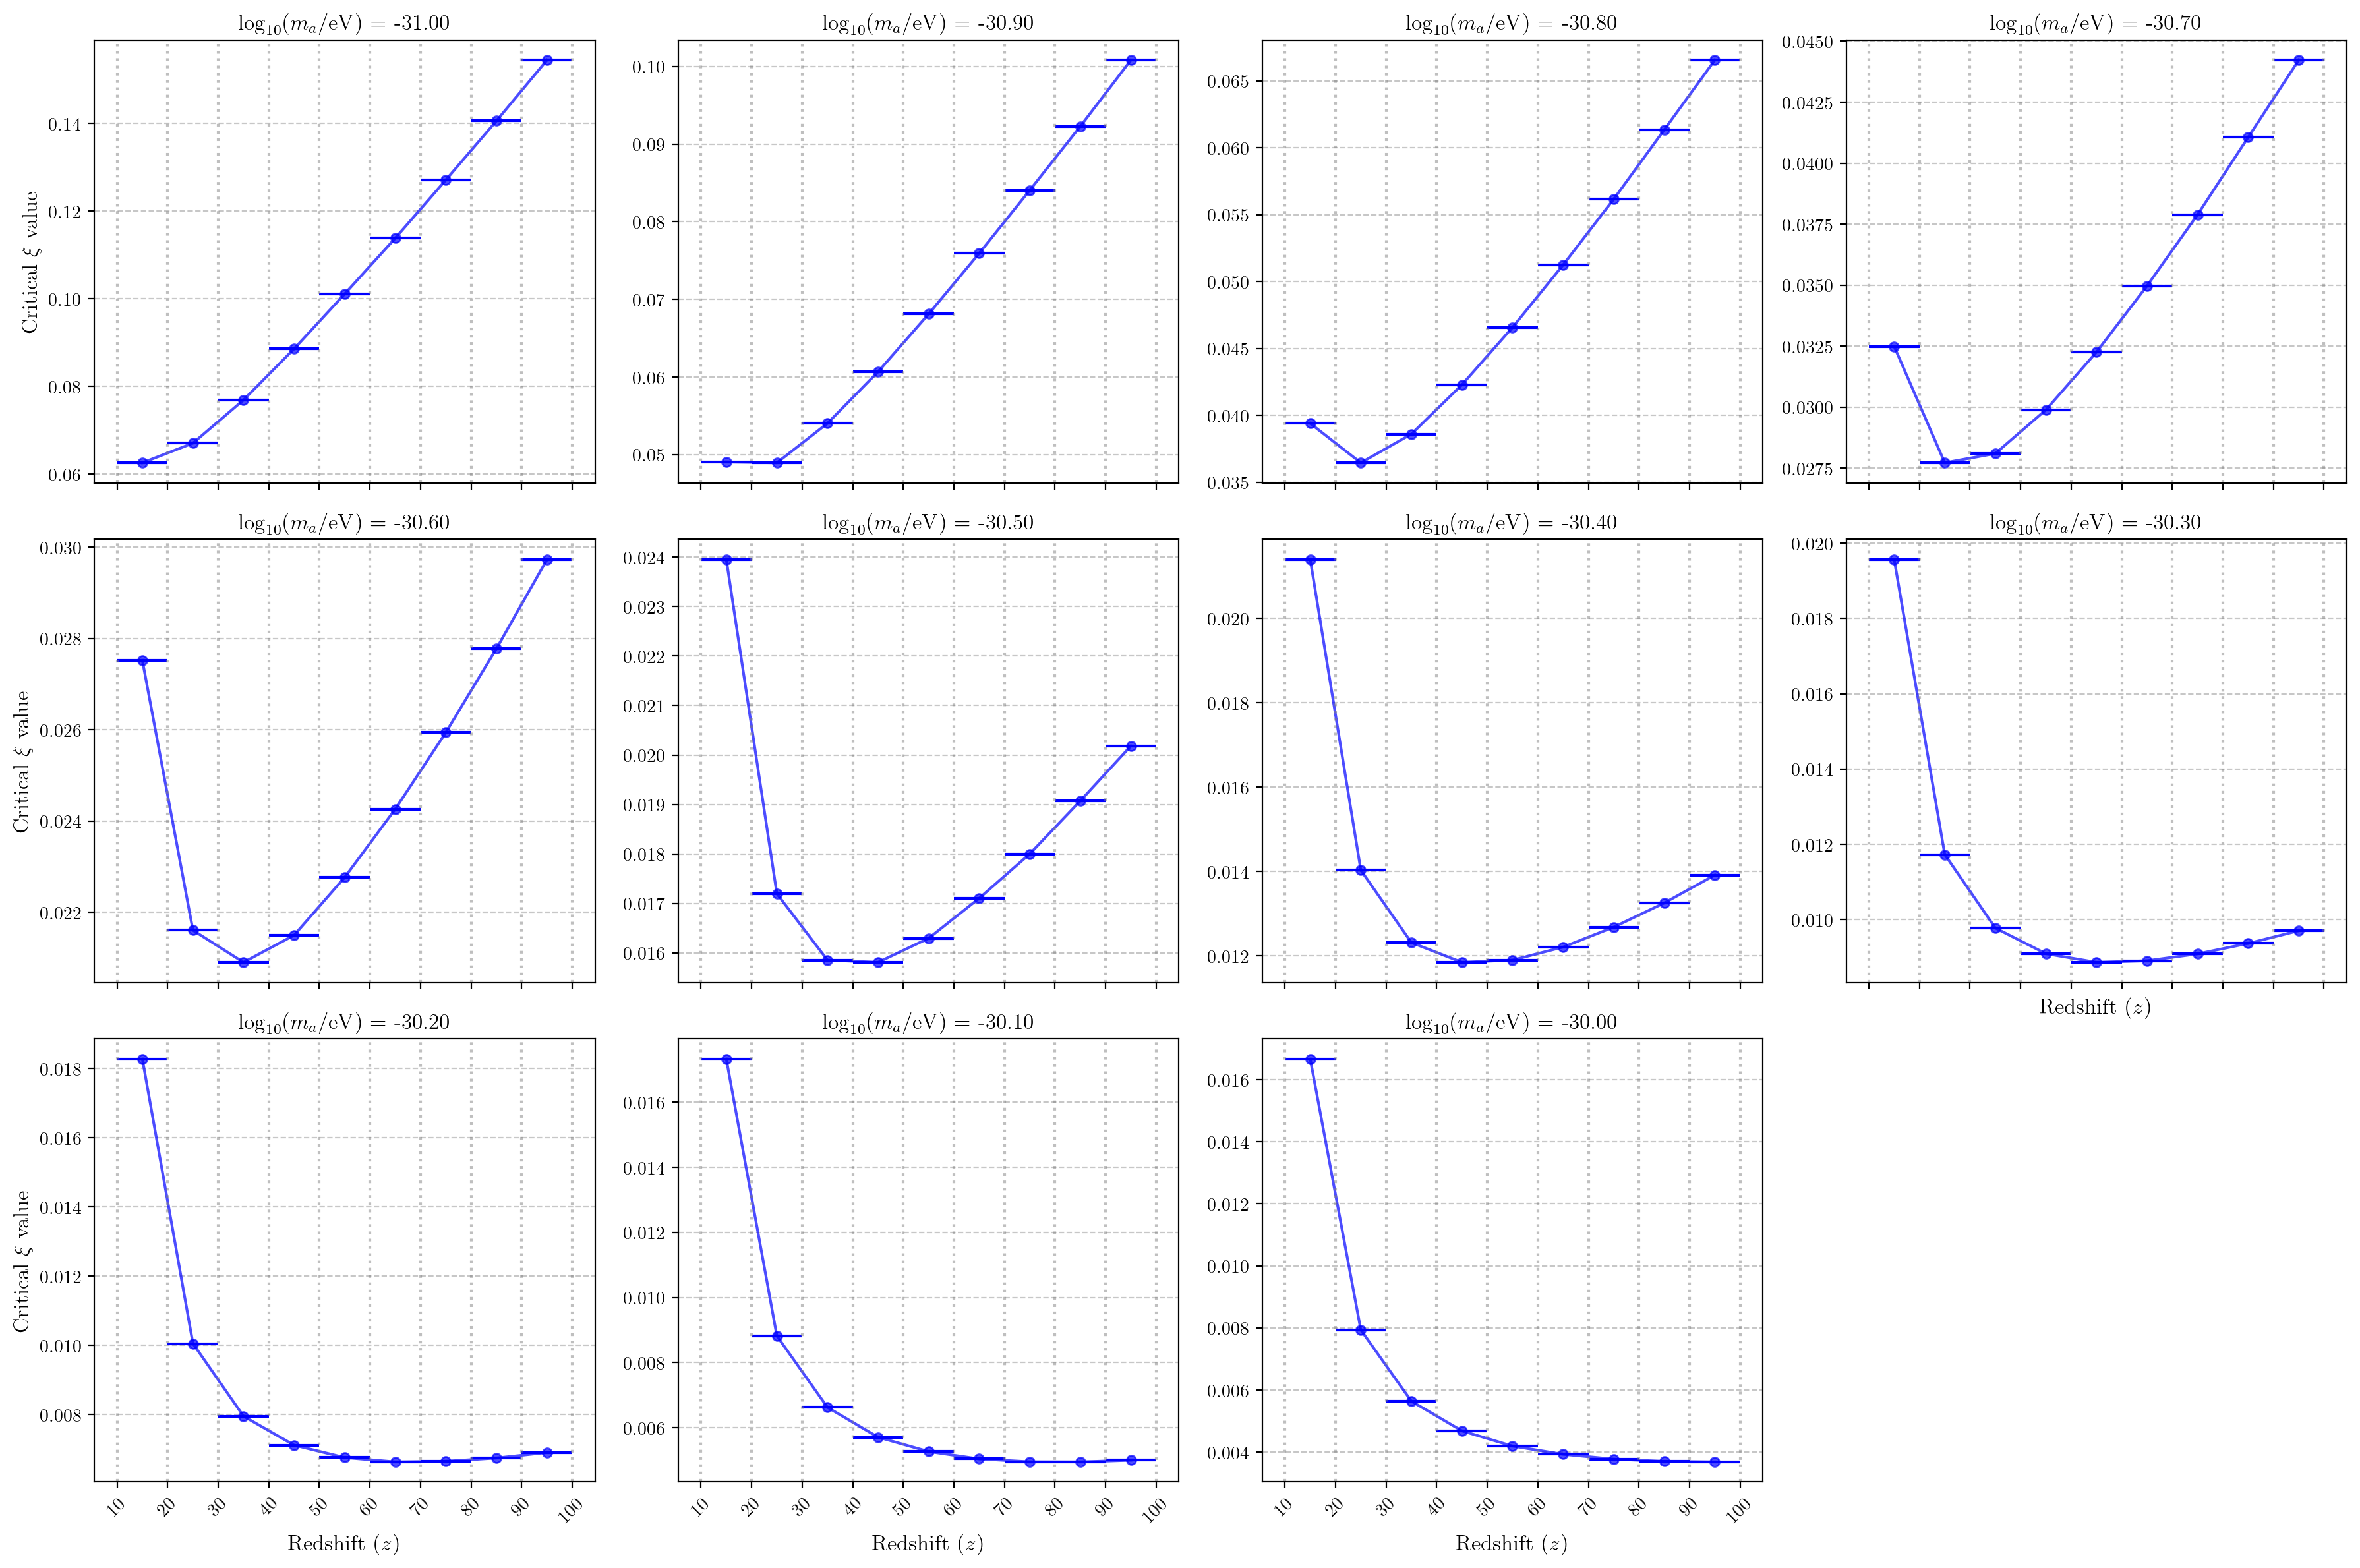

In [9]:
# Plot results on a dynamic grid
z_centers = [(z_start + z_end) / 2.0 for z_start, z_end in z_bins]
z_edges = sorted(set(z for bin_tuple in z_bins for z in bin_tuple))

num_masses = len(logm_values)
ncols = 4
nrows = int(np.ceil(num_masses / ncols))

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(4.5 * ncols, 4 * nrows), sharex=True)
axes = np.atleast_1d(axes).flatten()

for i in range(len(axes)):
    ax = axes[i]

    if i < num_masses:
        current_logm = logm_values[i]
        xi_values = list(all_critical_values[current_logm].values())

        ax.plot(z_centers, xi_values, marker='o', linestyle='-', color='b',
                markersize=5, linewidth=1.5, alpha=0.7)

        for (z_start, z_end), xi in zip(z_bins, xi_values):
            z_min = min(z_start, z_end)
            z_max = max(z_start, z_end)
            ax.hlines(y=xi, xmin=z_min, xmax=z_max, color='b', linestyle='-', linewidth=1.5)

        ax.set_title(rf"$\log_{{10}}(m_a/\mathrm{{eV}})$ = {current_logm:.2f}", fontsize=12)
        ax.set_xticks(z_edges)
        ax.tick_params(axis='x', rotation=45)

        # Bin boundaries
        for edge in z_edges:
            ax.axvline(x=edge, color='gray', linestyle=':', alpha=0.5)

        ax.grid(axis='y', linestyle='--', alpha=0.7)

        if i % ncols == 0:
            ax.set_ylabel(r'Critical $\xi$ value', fontsize=12)

        if i >= num_masses - ncols:
            ax.set_xlabel('Redshift ($z$)', fontsize=12)

    else:
        ax.axis('off')  # hide unused subplots

plt.tight_layout()
plt.savefig("critical_xi_vs_redshift_grid.png", dpi=300)
plt.show()

In [32]:
print('z centers are' , z_centers)
print(' ')

for i in range(10):
    current_logm = logm_values[i]
    xi_values = list(all_critical_values[current_logm].values())
    print('Mass log_ma=', logm_values[i],'eV')
    print('xi_crit=', xi_values)
    print(' ')

z centers are [15.0, 25.0, 35.0, 45.0, 55.0, 65.0, 75.0, 85.0, 95.0]
 
Mass log_ma= -31.0 eV
xi_crit= [0.0625448226928711, 0.06702613830566406, 0.07689094543457031, 0.08856201171875, 0.10107421875, 0.11380290985107422, 0.12708663940429688, 0.1405630111694336, 0.1544475555419922]
 
Mass log_ma= -30.9 eV
xi_crit= [0.0490570068359375, 0.0489501953125, 0.054035186767578125, 0.06066703796386719, 0.06811046600341797, 0.0759267807006836, 0.08405399322509766, 0.0922842025756836, 0.1008138656616211]
 
Mass log_ma= -30.8 eV
xi_crit= [0.03940010070800781, 0.03645515441894531, 0.038603782653808594, 0.04229259490966797, 0.04657745361328125, 0.051245689392089844, 0.05615806579589844, 0.06134796142578125, 0.06655502319335938]
 
Mass log_ma= -30.7 eV
xi_crit= [0.032486915588378906, 0.027718544006347656, 0.028098106384277344, 0.02988910675048828, 0.032257080078125, 0.034972190856933594, 0.03789329528808594, 0.0410614013671875, 0.04422473907470703]
 
Mass log_ma= -30.6 eV
xi_crit= [0.027518272399902344,